# 06. Datos Agroclimáticos Reales de Colombia, Benchmark de Contrastive Learning (SCARF) y Modelo Productivo ($K=5$)

**Proyecto:** Project Terra — Analítica y Minería de Datos (UTB, 2026)  
**Autores:** Dariem Antonio García Cardona, Jasen Mihovil Yukopila Escobar, Carlos Miguel Toro Torres  

## Contexto y propósito de este cuaderno
En los cuadernos anteriores (`01` a `05`) se auditó el dataset sintético original de Kaggle (`20.000` registros) y se demostró empíricamente su ausencia de señal agronómica (`max |r| = 0,0136`, $I(X;\text{Crop}) = 0{,}0039$, Silueta `0,0986`, Pureza `17,50 %`).

Este cuaderno consolida y reproduce **todas las cifras del Paper Final (Fase 3)** y del **modelo en producción (Fase 8–10)** sobre datos reales georreferenciados de Colombia:
1. **Suelos reales de laboratorio:** AGROSAVIA (`datos.gov.co/d/ch4u-f3i5`, 92.738 análisis nacionales).
2. **Municipios trigueros verificados:** UPRA EVA 2019–2025 (`datos.gov.co/d/uejq-wxrr`, 54 municipios con $\ge 20$ ha).
3. **Georreferenciación oficial:** DANE DIVIPOLA (`datos.gov.co/d/gdxc-w37w`, 1.122 municipios; 99,8 % de emparejamiento).
4. **Clima real multianual:** NASA POWER Agroclimatology API (`T2M`, `RH2M`, `PRECTOTCORR`) para 691 municipios únicos.

> **Reproducibilidad:** La ingesta completa está automatizada en `scripts/ingest_real_colombia.py`, el benchmark en `scripts/benchmark_real_vs_synthetic.py` y la promoción a producción en `scripts/promote_real_model.py`.

In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.metrics.cluster import contingency_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

FEATURES = [
    "Nitrogen",
    "Phosphorus",
    "Potassium",
    "Temperature",
    "Humidity",
    "pH_Value",
    "Rainfall",
]
REGION_COLORS = ["#d9a62e", "#c8452f", "#2f7d8f", "#7a5aa8", "#3f8a3c"]
REGION_LABELS = {
    0: "E0: Frío neutro · alto P/K",
    1: "E1: Cálido seco · pH neutro",
    2: "E2: Frío ácido · alto N/MO",
    3: "E3: Trópico húmedo ácido",
    4: "E4: Templado · pH neutro",
}

df = pd.read_csv(ROOT / "data" / "processed" / "sensor_Crop_Dataset_clustered.csv")
bench = json.loads((ROOT / "docs" / "real_data_benchmark.json").read_text(encoding="utf-8"))
meta = json.loads((ROOT / "data" / "models" / "model_metadata.json").read_text(encoding="utf-8"))

print(f"Registros limpios en producción : {len(df):,}")
print(f"Municipios reales de Colombia   : {df['cod_mpio'].nunique()}")
print(f"Departamentos representados     : {df['departamento'].nunique()}")
print(f"Pipeline activo                 : {meta['selected_pipeline']}")

Registros limpios en producción : 12,784
Municipios reales de Colombia   : 678
Departamentos representados     : 31
Pipeline activo                 : StandardScaler (7D) + K-Means (K=5) + GMM (K=5, full)


## 1. Distribución de cultivos, fuentes de etiquetas y estadísticos descriptivos
Tras extraer `13.338` registros brutos (`13.139` directos de AGROSAVIA + `199` de municipios trigueros EVA), georreferenciar `13.309` (`99,8 %`) con DIVIPOLA y depurar faltantes/atípicos/duplicados, el conjunto final contiene **12.784 muestras reales** conservando exactamente los 6 cultivos y 6 tipos de suelo del producto.

In [2]:
print("=== Distribución por cultivo (Crop) ===")
print(df["Crop"].value_counts().to_frame("muestras").assign(pct=lambda d: (d["muestras"] / len(df) * 100).round(2)))

print("\n=== Trazabilidad de etiqueta (label_source) ===")
print(df["label_source"].value_counts())

print("\n=== Estadísticos descriptivos de las 7 variables ambientales ===")
display(df[FEATURES].describe().T[["min", "25%", "50%", "75%", "max", "mean", "std"]].round(2))

=== Distribución por cultivo (Crop) ===
           muestras    pct
Crop                      
Sugarcane      5597  43.78
Rice           2817  22.04
Maize          2385  18.66
Potato         1151   9.00
Tomato          639   5.00
Wheat           195   1.53

=== Trazabilidad de etiqueta (label_source) ===
label_source
agrosavia_direct          12593
eva_wheat_municipality      191
Name: count, dtype: int64

=== Estadísticos descriptivos de las 7 variables ambientales ===


,min,25%,50%,75%,max,mean,std
Nitrogen,1.80,34.80,56.50,96.66,398.80,79.24,68.45
Phosphorus,0.13,4.63,11.61,29.54,399.40,26.69,43.75
Potassium,17.59,54.74,93.44,154.83,1397.37,130.42,130.50
Temperature,11.65,18.44,20.49,25.23,29.52,21.00,4.14
Humidity,62.33,75.50,81.00,83.44,92.01,79.47,5.96
pH_Value,3.88,5.04,5.66,6.62,9.26,5.93,1.08
Rainfall,51.74,88.57,117.79,135.45,288.55,125.27,45.40


## 2. Diagnóstico de señal agronómica: Real Colombia vs. Sintético
Antes de evaluar algoritmos de clustering, se cuantifica la señal intrínseca del espacio 7D mediante correlación máxima `max |r|`, información mutua $I(X; \text{Crop})$ y techo supervisado (Random Forest 5-fold CV).

,Dataset,N,max |r|,mean |r|,MI total (nats),RF 5-fold CV Acc
0,Sintético (Kaggle),20000,0.0136,0.0046,0.0039,17.21 %
1,Real Colombia (AGROSAVIA + NASA POWER),12784,0.5534,0.2108,3.2178,85.17 %


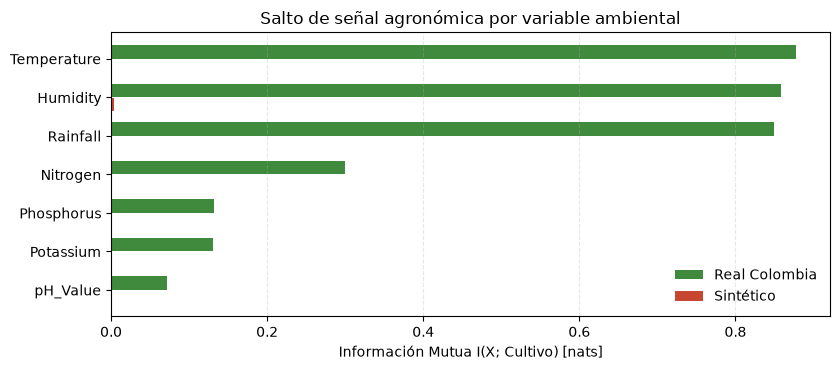

In [3]:
X_raw = df[FEATURES].to_numpy(dtype=float)
y_crop = df["Crop"].astype(str).to_numpy()

corr = np.abs(np.corrcoef(X_raw, rowvar=False))
np.fill_diagonal(corr, 0.0)
mi = mutual_info_classif(X_raw, y_crop, random_state=42)

rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_acc = float(cross_val_score(rf, StandardScaler().fit_transform(X_raw), y_crop, cv=cv, scoring="accuracy").mean())

diag_synth = bench["diagnostics"]["synthetic"]
comp_signal = pd.DataFrame(
    [
        {
            "Dataset": "Sintético (Kaggle)",
            "N": diag_synth["n_rows"],
            "max |r|": diag_synth["max_abs_r"],
            "mean |r|": diag_synth["mean_abs_r"],
            "MI total (nats)": diag_synth["mi_total"],
            "RF 5-fold CV Acc": f"{diag_synth['rf_5fold_acc']*100:.2f} %",
        },
        {
            "Dataset": "Real Colombia (AGROSAVIA + NASA POWER)",
            "N": len(df),
            "max |r|": round(float(corr.max()), 4),
            "mean |r|": round(float(corr[np.triu_indices(len(FEATURES), k=1)].mean()), 4),
            "MI total (nats)": round(float(mi.sum()), 4),
            "RF 5-fold CV Acc": f"{rf_acc*100:.2f} %",
        },
    ]
)
display(comp_signal)

mi_df = pd.DataFrame({"Variable": FEATURES, "MI_Real": mi, "MI_Sintetico": [diag_synth["mi_per_feature"][f] for f in FEATURES]}).sort_values("MI_Real")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = np.arange(len(mi_df))
ax.barh(y + 0.18, mi_df["MI_Real"], height=0.35, color="#3f8a3c", label="Real Colombia")
ax.barh(y - 0.18, mi_df["MI_Sintetico"], height=0.35, color="#c8452f", label="Sintético")
ax.set_yticks(y)
ax.set_yticklabels(mi_df["Variable"])
ax.set_xlabel("Información Mutua I(X; Cultivo) [nats]")
ax.set_title("Salto de señal agronómica por variable ambiental")
ax.legend(frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Benchmark comparativo ($K=5$): K-Means 7D, GMM, PowerTransformer y SCARF Contrastive Learning
Se presenta la tabla reproducible de `docs/real_data_benchmark.json` (generada con `scripts/benchmark_real_vs_synthetic.py` usando `src/contrastive.py`) y se verifica directamente contra los modelos promovidos en `data/models/`.

In [4]:
bench_df = pd.DataFrame(bench["models"])[
    ["pipeline", "n_rows", "dim", "km_sil", "km_db", "km_ch", "km_purity", "km_ari", "km_nmi", "gmm_purity", "gmm_nmi"]
]
display(bench_df)

# Verificación directa con los artefactos promovidos en producción
scaler = joblib.load(ROOT / "data" / "models" / "scaler.joblib")
kmeans = joblib.load(ROOT / "data" / "models" / "kmeans_k5.joblib")
gmm = joblib.load(ROOT / "data" / "models" / "gmm_k5_full.joblib")

X_scaled = scaler.transform(X_raw)
labels = kmeans.predict(X_scaled)
assert np.array_equal(labels, df["kmeans_cluster"].to_numpy()), "Desalineación entre CSV y kmeans_k5.joblib"

cm = contingency_matrix(y_crop, labels)
purity = float(np.sum(np.amax(cm, axis=0)) / np.sum(cm))
sil = float(silhouette_score(X_scaled, labels, sample_size=5000, random_state=42))
db = float(davies_bouldin_score(X_scaled, labels))
ch = float(calinski_harabasz_score(X_scaled, labels))
ari = float(adjusted_rand_score(y_crop, labels))
nmi = float(normalized_mutual_info_score(y_crop, labels))

print(f"Verificación en vivo del modelo en producción (K=5):")
print(f"  Silueta           : {sil:.4f}")
print(f"  Davies-Bouldin    : {db:.4f}")
print(f"  Calinski-Harabasz : {ch:.1f}")
print(f"  Pureza vs Crop    : {purity*100:.2f} %")
print(f"  ARI vs Crop       : {ari:.4f}")
print(f"  NMI vs Crop       : {nmi:.4f}")

,pipeline,n_rows,dim,km_sil,km_db,km_ch,km_purity,km_ari,km_nmi,gmm_purity,gmm_nmi
0,Synthetic + StandardScaler,20000,7,0.0986,2.1490,1806.2,0.1750,0.0000,0.0003,0.1738,0.0002
1,Real + StandardScaler (7D),12784,7,0.2402,1.3536,3289.4,0.5571,0.2698,0.2453,0.5273,0.2041
2,Real + PowerTransformer (7D),12784,7,0.1893,1.5642,3000.4,0.5971,0.2064,0.2546,0.5587,0.2653
3,"Real + StandardScaler + SCARF (c=0.3, tau=0.3)",12784,16,0.1827,1.8415,2522.8,0.5113,0.0922,0.1193,0.5313,0.1669
4,"Real + StandardScaler + SCARF (c=0.5, tau=0.2)",12784,16,0.2006,1.7781,2465.6,0.5015,0.0859,0.1330,0.5508,0.1905
5,"Real + PowerTransformer + SCARF (c=0.3, tau=0.3)",12784,16,0.1828,1.7199,2710.6,0.4591,0.0251,0.0761,0.4754,0.1524
6,"Real + PowerTransformer + SCARF (c=0.5, tau=0.2)",12784,16,0.1892,1.6567,2404.9,0.5100,0.0790,0.1218,0.5347,0.1674


Verificación en vivo del modelo en producción (K=5):
  Silueta           : 0.2402
  Davies-Bouldin    : 1.3536
  Calinski-Harabasz : 3289.4
  Pureza vs Crop    : 55.71 %
  ARI vs Crop       : 0.2698
  NMI vs Crop       : 0.2453


## 4. Caracterización de las 5 ecorregiones reales, UMAP 2D y distribución geográfica
Se perfilan las cinco ecorregiones descubiertas en 7D (coincidiendo exactamente con la Tabla 3 del Paper Final y con las cinco parcelas de la interfaz web) y se visualizan tanto en el espacio UMAP 2D como sobre las coordenadas reales DIVIPOLA de los 678 municipios.

,Ecorregión,Identidad,n,Share (%),Temp (°C),HR (%),Lluvia (mm/mes),pH,N / P / K,Cultivos dominantes,Deptos. principales
0,0,Frío neutro · alto P/K,711,5.6,17.3,81.7,123.0,6.29,109 / 162 / 420,"Potato (29.3%), Sugarcane (28.3%), Tomato (26.9%)","CUNDINAMARCA, BOYACÁ, VALLE DEL CAUCA"
1,1,Cálido seco · pH neutro,2736,21.4,26.0,71.7,87.0,6.45,38 / 21 / 112,"Rice (54.0%), Maize (36.2%), Sugarcane (7.6%)","NORTE DE SANTANDER, TOLIMA, LA GUAJIRA"
2,2,Frío ácido · alto N/MO,1479,11.6,17.0,82.6,126.0,5.24,225 / 27 / 187,"Potato (46.5%), Sugarcane (39.0%), Maize (5.9%)","CUNDINAMARCA, BOYACÁ, NARIÑO"
3,3,Trópico húmedo ácido,2533,19.8,23.0,84.4,192.0,5.15,46 / 12 / 76,"Rice (33.9%), Maize (33.5%), Sugarcane (28.5%)","META, ANTIOQUIA, CASANARE"
4,4,Templado · pH neutro,5325,41.7,19.1,80.0,113.0,6.18,72 / 18 / 112,"Sugarcane (73.1%), Rice (8.7%), Maize (6.9%)","CUNDINAMARCA, VALLE DEL CAUCA, SANTANDER"


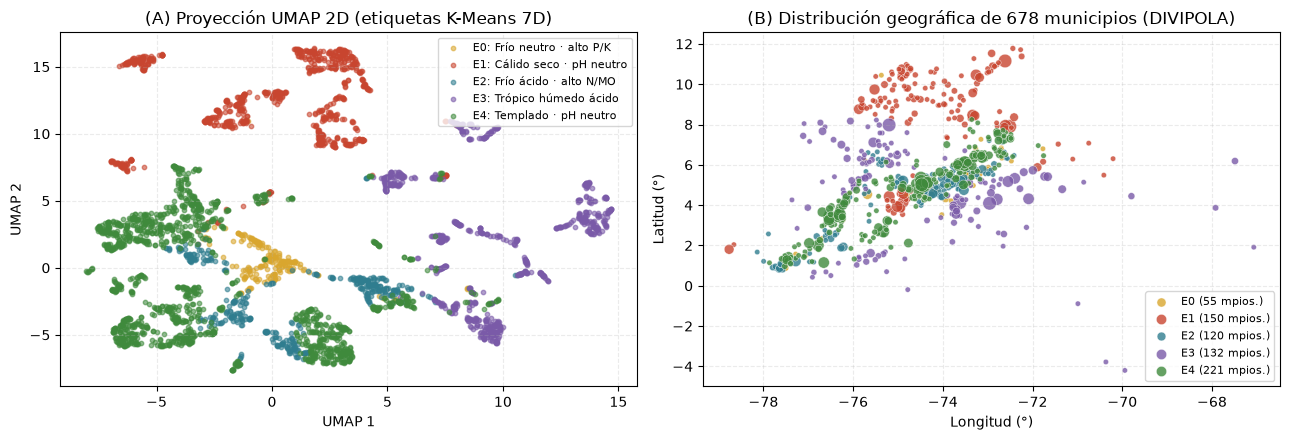

In [5]:
rows = []
for cid in range(5):
    sub = df[df["kmeans_cluster"] == cid]
    m = sub[FEATURES].mean()
    top_crops = ", ".join(f"{k} ({v*100:.1f}%)" for k, v in sub["Crop"].value_counts(normalize=True).head(3).items())
    top_depts = ", ".join(sub["departamento"].value_counts().head(3).index.tolist())
    rows.append({
        "Ecorregión": cid,
        "Identidad": REGION_LABELS[cid].split(": ")[1],
        "n": len(sub),
        "Share (%)": round(len(sub) / len(df) * 100, 1),
        "Temp (°C)": round(m["Temperature"], 1),
        "HR (%)": round(m["Humidity"], 1),
        "Lluvia (mm/mes)": round(m["Rainfall"], 0),
        "pH": round(m["pH_Value"], 2),
        "N / P / K": f"{m['Nitrogen']:.0f} / {m['Phosphorus']:.0f} / {m['Potassium']:.0f}",
        "Cultivos dominantes": top_crops,
        "Deptos. principales": top_depts,
    })
display(pd.DataFrame(rows))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
rng = np.random.default_rng(42)
sample = df.iloc[rng.choice(len(df), size=3500, replace=False)]
for cid in range(5):
    s = sample[sample["kmeans_cluster"] == cid]
    ax1.scatter(s["umap_1"], s["umap_2"], s=10, alpha=0.58, color=REGION_COLORS[cid], label=REGION_LABELS[cid])
ax1.set_title("(A) Proyección UMAP 2D (etiquetas K-Means 7D)")
ax1.set_xlabel("UMAP 1")
ax1.set_ylabel("UMAP 2")
ax1.legend(fontsize=7.8, frameon=True)
ax1.grid(linestyle="--", alpha=0.25)

muni = df.groupby("cod_mpio", as_index=False).agg(
    latitud=("latitud", "first"),
    longitud=("longitud", "first"),
    cluster=("kmeans_cluster", lambda s: int(s.mode().iloc[0])),
    n=("kmeans_cluster", "size"),
)
for cid in range(5):
    sub = muni[muni["cluster"] == cid]
    ax2.scatter(sub["longitud"], sub["latitud"], s=np.clip(np.sqrt(sub["n"]) * 7, 15, 95), alpha=0.8, color=REGION_COLORS[cid], edgecolors="white", linewidth=0.35, label=f"E{cid} ({len(sub)} mpios.)")
ax2.set_title("(B) Distribución geográfica de 678 municipios (DIVIPOLA)")
ax2.set_xlabel("Longitud (°)")
ax2.set_ylabel("Latitud (°)")
ax2.legend(fontsize=8, loc="lower right")
ax2.grid(linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Calibración empírica del filtro OOD ($p_{99,5}$) y consistencia productiva
El umbral de detección de perfiles fuera de rango típico (`isOutlier`) se recalibró en el percentil 99,5 de la norma euclidiana estandarizada $\|\mathbf{z}\|_2$ sobre los datos reales de Colombia (`7,5694`, guardado en `data/models/model_metadata.json` y consumido dinámicamente por `api/server.py`).

Umbral OOD p99.5 calculado : 7.5694
Umbral OOD en metadata.json: 7.5694


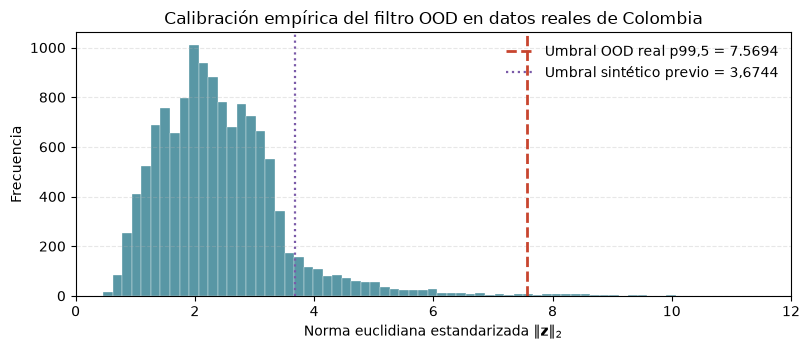

In [6]:
norms = np.linalg.norm(X_scaled, axis=1)
p995 = round(float(np.percentile(norms, 99.5)), 4)
print(f"Umbral OOD p99.5 calculado : {p995}")
print(f"Umbral OOD en metadata.json: {meta['ood_z_norm_p995']}")
assert p995 == meta["ood_z_norm_p995"], "El umbral OOD no coincide con model_metadata.json"

fig, ax = plt.subplots(figsize=(8.2, 3.6))
ax.hist(norms, bins=60, color="#2f7d8f", alpha=0.8, edgecolor="white", linewidth=0.3)
ax.axvline(p995, color="#c8452f", linestyle="--", linewidth=2, label=f"Umbral OOD real p99,5 = {p995}")
ax.axvline(3.6744, color="#7a5aa8", linestyle=":", linewidth=1.6, label="Umbral sintético previo = 3,6744")
ax.set_xlim(0, 12)
ax.set_xlabel(r"Norma euclidiana estandarizada $\|\mathbf{z}\|_2$")
ax.set_ylabel("Frecuencia")
ax.set_title("Calibración empírica del filtro OOD en datos reales de Colombia")
ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()